In [13]:
from astropy.io import fits
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

In [3]:
# Path to data:
path = '/data-fast/dragon/vicente/iongrid/runs/run_20261029_htc_lhs/results'

In [8]:
# Files:
emission_file = 'emission.fits'
line_emission_file = 'linem_clean.fits'
transmission_file = 'optdepth_clean.fits'

# Load data:
files = [line_emission_file, transmission_file]
spectra = []
param_names = []
param_values = []
param_units = []
for k, file_name in enumerate(files):
    with fits.open(os.path.join(path, file_name)) as hdul:
        # Extract all parameters directly from the FITS table:
        param_names.append(np.array(hdul['PARAMS'].columns.names))
        param_values.append(pd.DataFrame(hdul['PARAMS'].data))
        param_units.append(np.array(hdul['PARAMS'].columns.units))
        energy = hdul['ENERGY'].data
        spectra.append(hdul['SPECTRA'].data)

# Unpack parameter sets for explicit referencing:
param_names_em, param_names_abs = param_names[0], param_names[1]
param_values_em, param_values_abs = param_values[0], param_values[1]
param_units_em, param_units_abs = param_units[0], param_units[1]
# Create filtered lists for generating widgets and plot titles:
plot_params_em = [name for name in param_names_em if name.lower() != 'POINT_ID']
plot_params_em = [name for name in param_names_em if name.lower() != 'population']
plot_params_abs = [name for name in param_names_abs if name.lower() != 'POINT_ID']
plot_params_abs = [name for name in param_names_abs if name.lower() != 'population']

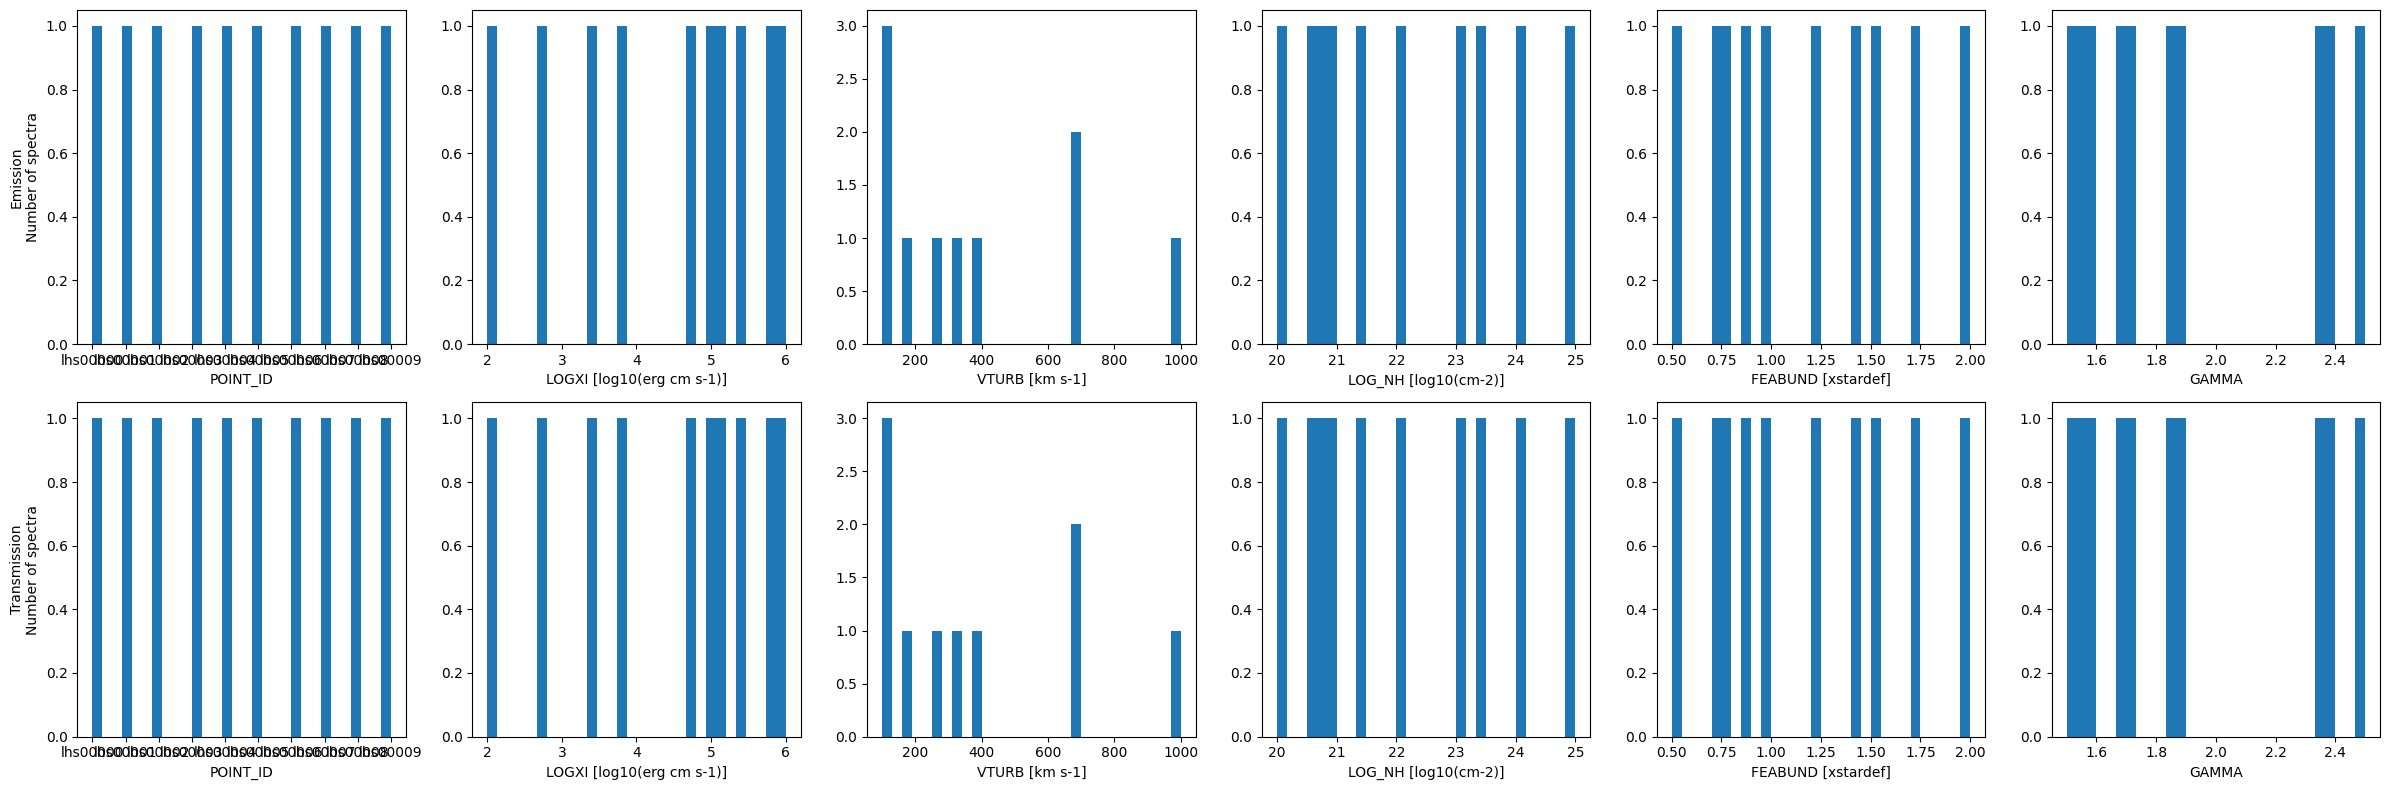

In [10]:
# Take a first look at the parameter distribution:
components = [
    ('Emission', param_names[0], param_values[0], param_units[0]),
    ('Transmission', param_names[1], param_values[1], param_units[1])
]
max_cols = max(len(param_names[0]), len(param_names[1]))
fig, axs = plt.subplots(nrows=2, ncols=max_cols, figsize=(4 * max_cols, 8), squeeze=False)
nbins = 30
for row_idx, (title, names, values, units) in enumerate(components):
    for k in range(max_cols):
        if k < len(names):
            col_name = names[k]
            unit = units[k]
            # Index by column name or using values.iloc[:, k] for pandas DataFrames
            axs[row_idx, k].hist(values[col_name], bins=nbins)
            # Add parameter name and FITS unit to x-axis:
            if unit is not None and str(unit).strip():
                xlabel = f'{col_name} [{unit}]'
            else:
                xlabel = col_name
            axs[row_idx, k].set_xlabel(xlabel)
            if k == 0:
                axs[row_idx, k].set_ylabel(f'{title}\nNumber of spectra')
        else:
            axs[row_idx, k].axis('off') 
plt.tight_layout()
plt.show()

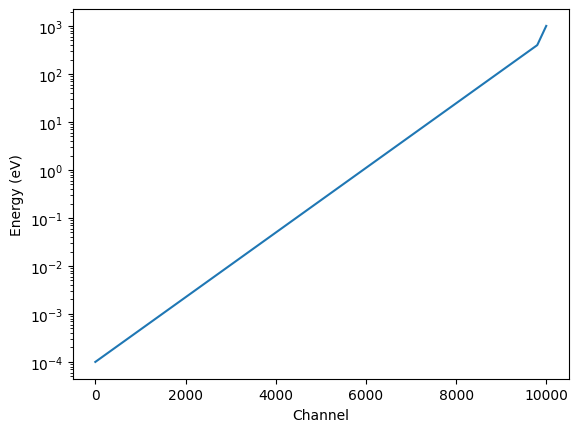

In [11]:
# Take a first look at the energy array:
plt.plot(np.linspace(0, len(energy) - 1, len(energy)), energy)
plt.xlabel('Channel')
plt.ylabel('Energy (eV)')
plt.yscale('log')
plt.show()

In [12]:
# Set units of energy array to keV:
energy = energy / 1000

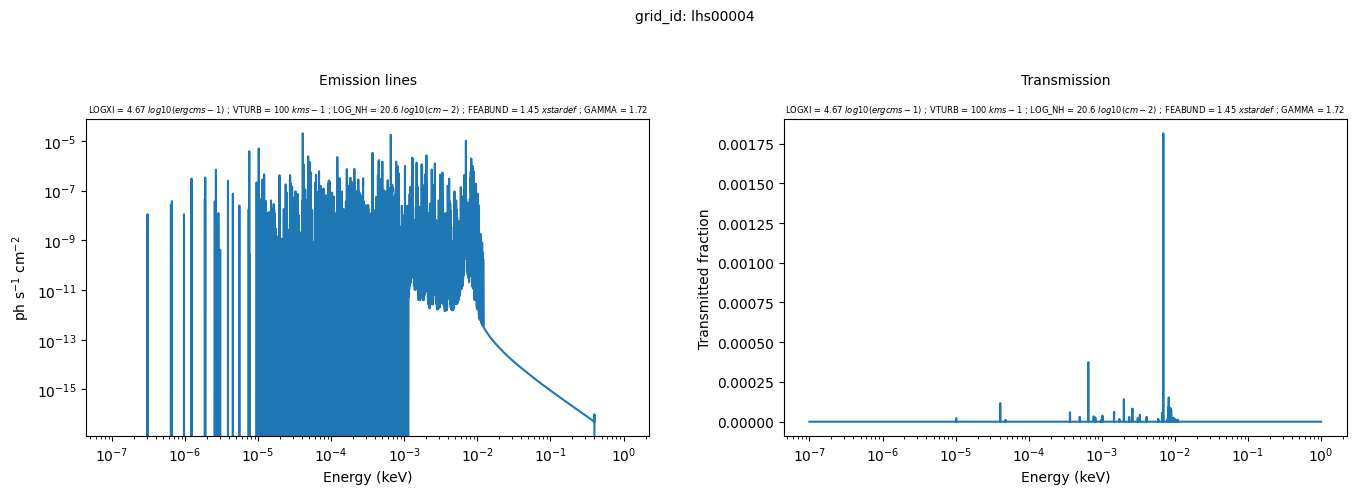

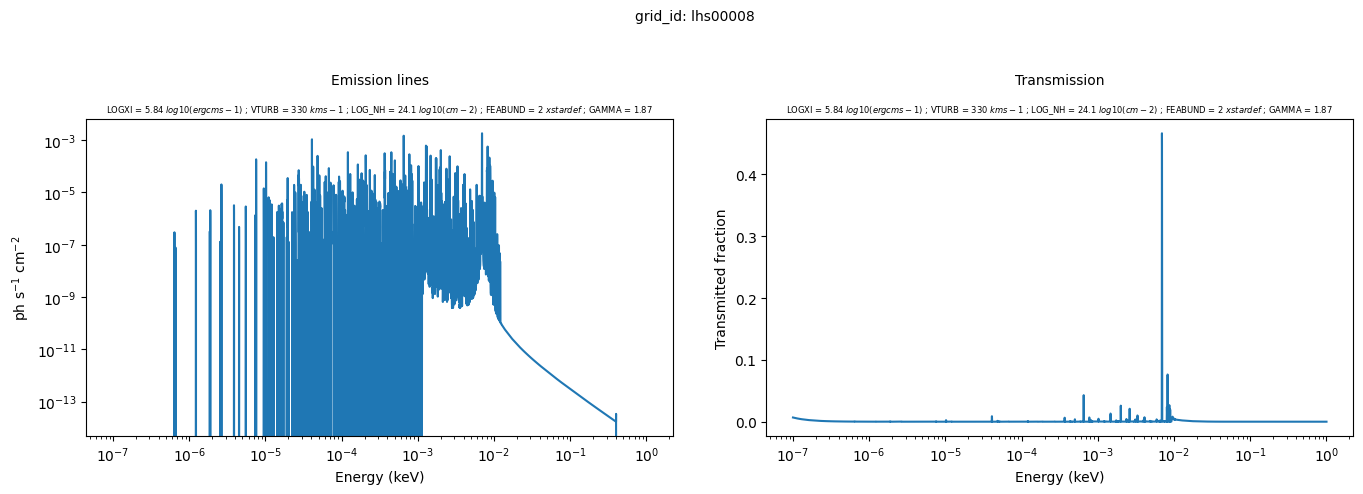

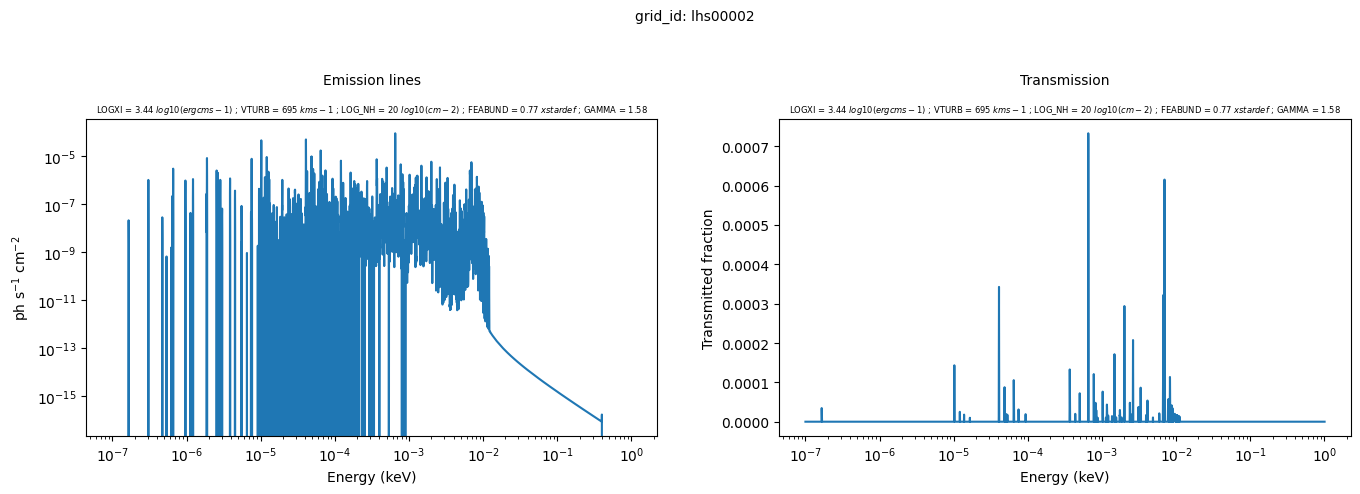

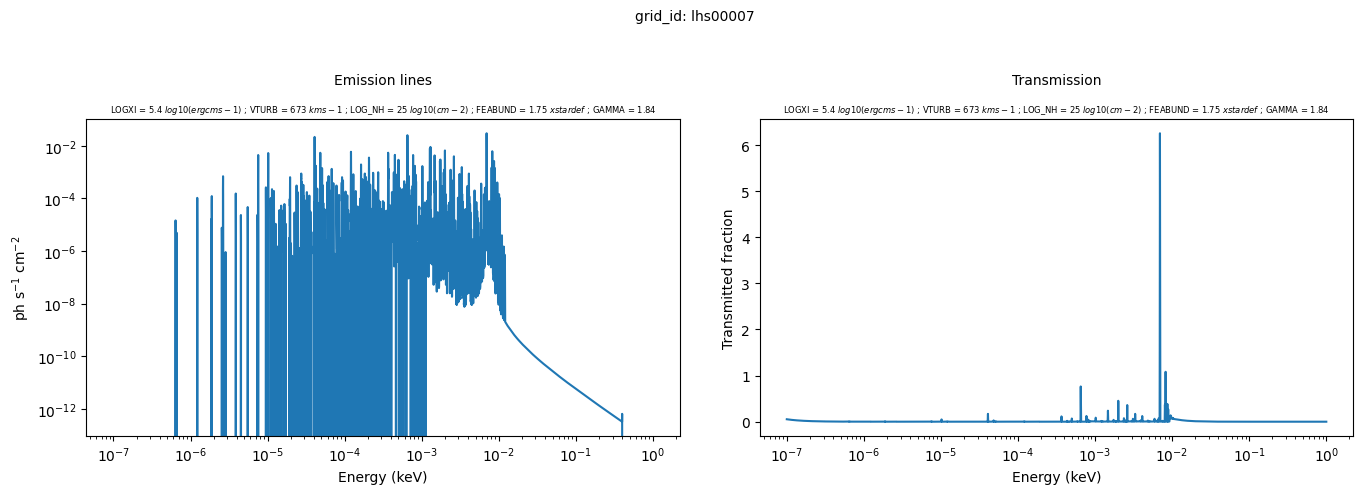

In [ ]:
# Take a first look at some random spectra:
number_spectra = 20

# Find common POINT_IDs between emission and absorption components:
common_ids = set(param_values[0]['POINT_ID']).intersection(set(param_values[1]['POINT_ID']))
sampled_ids = random.sample(sorted(list(common_ids)), min(number_spectra, len(common_ids)))

labels = ['Emission lines', 'Transmission']
# Parameters to exclude from the panel titles:
excluded_params = ['point_id', 'population']

for gid in sampled_ids:
    # Get all matching indices for this POINT_ID:
    matching_em = param_values[0].index[param_values[0]['POINT_ID'] == gid]
    matching_abs = param_values[1].index[param_values[1]['POINT_ID'] == gid]
    # Randomly select one index from all available angle/geometry entries:
    idx_em = random.choice(matching_em)
    idx_abs = random.choice(matching_abs)
    indices = [idx_em, idx_abs]
    # Figure:
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))
    for j in range(2):
        k = indices[j]
        # Build parameter string, including FITS units:
        param_items = []
        for name, val, unit in zip(param_names[j], param_values[j].iloc[k],param_units[j]):
            if name.lower() in excluded_params:
                continue
            # Format numbers cleanly:
            val_str = (f"{val:.3g}" if isinstance(val, (float, np.floating)) else f"{val}")
            # Append parameter name, value, and unit:
            if unit is not None and str(unit).strip():
                param_items.append(f"{name} = {val_str} ${unit}$")
            else:
                param_items.append(f"{name} = {val_str}")
        param_str = " ; ".join(param_items)
        # Plot spectrum:
        axs[j].plot(energy, spectra[j][k])
        axs[j].set_xscale('log')
        axs[j].set_xlabel('Energy (keV)')
        # Component name:
        axs[j].set_title(labels[j], fontsize=10, pad=25)
        # Parameter information below the component name:
        axs[j].text(0.5, 1.01, param_str, transform=axs[j].transAxes, fontsize=6, ha='center', va='bottom', wrap=True)
        if j == 0:
            axs[j].set_ylabel(r'$\mathrm{ph\ s^{-1}\ cm^{-2}}$')
            axs[j].set_yscale('log')
        else:
            axs[j].set_ylabel('Transmitted fraction')

    # Add POINT_ID as a small, regular-weight figure supertitle:
    fig.suptitle(f'grid_id: {gid}', fontsize=10)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()